1. Generate wavefront
   - fixed low-order aberration
   - random atmospheric phase screen

2. Measure wavefront slopes
   - geometric Shack-Hartmann model

3. Reconstruct wavefront
   - response matrix
   - least-squares modal reconstruction

4. Analyze limitations
   - noise sensitivity
   - lenslet sampling
   - modal truncation / fitting error

5. Demonstrate low-order AO correction
   - before/after residual RMS
   - optional PSF and Strehl ratio

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import importlib

import zernike
import phase_screen
import reconstruction

importlib.reload(zernike)
importlib.reload(phase_screen)
importlib.reload(reconstruction)

from zernike import (
    make_pupil_grid,
    zernike_named_modes,
    synthesize_wavefront,
)

from phase_screen import fourier_phase_screen

from reconstruction import (
    build_response_matrix,
    measure_slopes,
    reconstruct_wavefront,
    residual_wavefront,
    rms,
)

In [2]:
def setup_pupil_and_modes(N=256, diameter=1.0):
    """
    Create pupil grid and low-order Zernike-like modes.
    """
    X, Y, rho, theta, mask, dx = make_pupil_grid(
        N=N,
        diameter=diameter,
    )

    modes = zernike_named_modes(
        rho,
        theta,
        mask,
        include_piston=False,
        normalized=True,
    )

    return X, Y, rho, theta, mask, dx, modes


def make_fixed_zernike_wavefront(modes, mask):
    """
    Deterministic low-order wavefront.

    This is useful for checking whether the reconstruction pipeline works.
    """
    true_coeffs = {
        "tip_x": 0.05,
        "tip_y": -0.03,
        "defocus": 0.25,
        "astig_45": -0.12,
        "astig_0": 0.08,
        "coma_x": 0.10,
        "coma_y": -0.07,
        "spherical": 0.04,
    }

    W_true = synthesize_wavefront(
        modes,
        true_coeffs,
        mask,
        remove_mean=True,
    )

    return W_true, true_coeffs


def make_random_atmospheric_wavefront(
    N,
    dx,
    diameter=1.0,
    r0=0.20,
    L0=25.0,
    seed=4,
    target_rms_rad=1.0,
):
    """
    Random atmospheric phase screen.

    Unit:
        radians of optical phase.

    Changing seed gives a different turbulence realization.
    """
    W_atm, _, _, _ = fourier_phase_screen(
        N=N,
        delta=dx,
        r0=r0,
        L0=L0,
        diameter=diameter,
        seed=seed,
        target_rms_rad=target_rms_rad,
    )

    return W_atm


def run_wfs_reconstruction(
    W_true,
    X,
    Y,
    mask,
    modes,
    n_lenslets=12,
    min_fill=0.5,
    noise_std=0.0,
    seed=1,
    rcond=1e-4,
):
    """
    Full geometric Shack-Hartmann WFS reconstruction pipeline.

    Steps:
        1. Measure local slopes
        2. Build response matrix
        3. Reconstruct modal coefficients
        4. Synthesize reconstructed wavefront
        5. Compute residual wavefront
    """
    centers, slopes = measure_slopes(
        W_true,
        mask,
        X,
        Y,
        n_lenslets=n_lenslets,
        min_fill=min_fill,
        noise_std=noise_std,
        seed=seed,
    )

    A, names, _ = build_response_matrix(
        modes,
        mask,
        X,
        Y,
        n_lenslets=n_lenslets,
        min_fill=min_fill,
    )

    coeffs, W_rec, residuals, rank, singular_values = reconstruct_wavefront(
        slopes,
        A,
        modes,
        names,
        mask,
        rcond=rcond,
    )

    res = residual_wavefront(W_true, W_rec, mask)

    return {
        "centers": centers,
        "slopes": slopes,
        "A": A,
        "names": names,
        "coeffs": coeffs,
        "W_rec": W_rec,
        "residual": res,
        "rank": rank,
        "singular_values": singular_values,
        "input_rms": rms(W_true, mask),
        "residual_rms": rms(res, mask),
    }


def plot_reconstruction_result(W_true, result, X, Y, title_prefix=""):
    """
    Plot wavefront, slopes, reconstruction, and residual.
    """
    W_rec = result["W_rec"]
    res = result["residual"]
    centers = result["centers"]
    slopes = result["slopes"]

    extent = [
        np.nanmin(X),
        np.nanmax(X),
        np.nanmin(Y),
        np.nanmax(Y),
    ]

    fig, axes = plt.subplots(1, 4, figsize=(17, 4))

    im0 = axes[0].imshow(
        W_true,
        extent=extent,
        origin="lower",
    )
    axes[0].set_title(f"{title_prefix}True wavefront")
    axes[0].set_xlabel("x")
    axes[0].set_ylabel("y")
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    axes[1].quiver(
        centers[:, 0],
        centers[:, 1],
        slopes[:, 0],
        slopes[:, 1],
    )
    axes[1].set_title("SH-WFS slopes")
    axes[1].set_aspect("equal")
    axes[1].set_xlim(extent[0], extent[1])
    axes[1].set_ylim(extent[2], extent[3])
    axes[1].set_xlabel("x")
    axes[1].set_ylabel("y")

    im2 = axes[2].imshow(
        W_rec,
        extent=extent,
        origin="lower",
    )
    axes[2].set_title("Reconstructed")
    axes[2].set_xlabel("x")
    axes[2].set_ylabel("y")
    plt.colorbar(im2, ax=axes[2], fraction=0.046)

    im3 = axes[3].imshow(
        res,
        extent=extent,
        origin="lower",
    )
    axes[3].set_title("Residual")
    axes[3].set_xlabel("x")
    axes[3].set_ylabel("y")
    plt.colorbar(im3, ax=axes[3], fraction=0.046)

    plt.tight_layout()
    plt.show()

In [3]:
N = 256
diameter = 1.0

X, Y, rho, theta, mask, dx, modes = setup_pupil_and_modes(
    N=N,
    diameter=diameter,
)

W_fixed, true_coeffs = make_fixed_zernike_wavefront(
    modes,
    mask,
)

W_atm = make_random_atmospheric_wavefront(
    N=N,
    dx=dx,
    diameter=diameter,
    r0=0.20,
    L0=25.0,
    seed=4,
    target_rms_rad=1.0,
)

print(f"Fixed Zernike-like wavefront RMS: {rms(W_fixed, mask):.4f}")
print(f"Random atmospheric wavefront RMS: {rms(W_atm, mask):.4f}")

Fixed Zernike-like wavefront RMS: 0.3210
Random atmospheric wavefront RMS: 0.9999


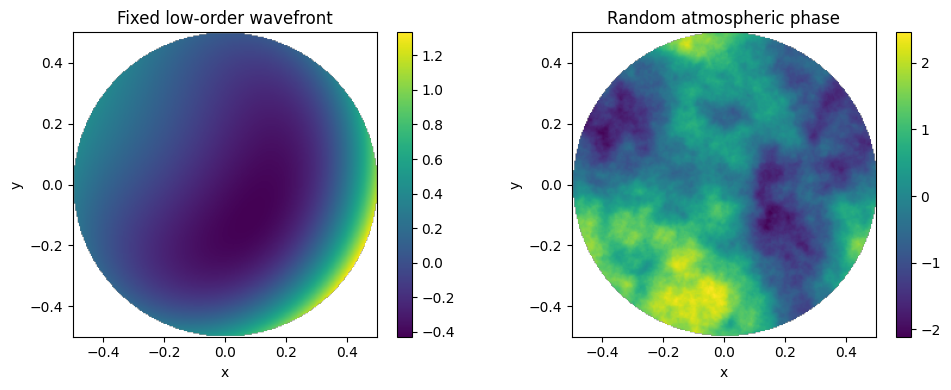

In [4]:
extent = [
    np.nanmin(X),
    np.nanmax(X),
    np.nanmin(Y),
    np.nanmax(Y),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im0 = axes[0].imshow(
    W_fixed,
    extent=extent,
    origin="lower",
)
axes[0].set_title("Fixed low-order wavefront")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(
    W_atm,
    extent=extent,
    origin="lower",
)
axes[1].set_title("Random atmospheric phase")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

In [5]:
#Sanity check
result_fixed = run_wfs_reconstruction(
    W_fixed,
    X,
    Y,
    mask,
    modes,
    n_lenslets=12,
    noise_std=0.0,
    seed=1,
)

print("Estimated coefficients")
print("----------------------")

for name, coeff in zip(result_fixed["names"], result_fixed["coeffs"]):
    true_value = true_coeffs.get(name, 0.0)
    print(f"{name:12s}: true = {true_value:+.4f}, estimated = {coeff:+.4f}")

print()
print(f"Input RMS:    {result_fixed['input_rms']:.4e}")
print(f"Residual RMS: {result_fixed['residual_rms']:.4e}")
print(f"Rank:         {result_fixed['rank']}")

Estimated coefficients
----------------------
tip_x       : true = +0.0500, estimated = +0.0500
tip_y       : true = -0.0300, estimated = -0.0300
defocus     : true = +0.2500, estimated = +0.2500
astig_45    : true = -0.1200, estimated = -0.1200
astig_0     : true = +0.0800, estimated = +0.0800
coma_x      : true = +0.1000, estimated = +0.1000
coma_y      : true = -0.0700, estimated = -0.0700
trefoil_x   : true = +0.0000, estimated = +0.0000
trefoil_y   : true = +0.0000, estimated = -0.0000
spherical   : true = +0.0400, estimated = +0.0400

Input RMS:    3.2096e-01
Residual RMS: 4.5609e-05
Rank:         10


Noise Sensitivity Test

In [6]:
#Check how WFS slope measurement noise degrades reconstruction results.
def noise_sensitivity_curve(
    W_true,
    X,
    Y,
    mask,
    modes,
    n_lenslets=12,
    noise_values=None,
    n_trials=10,
):
    """
    Scan measurement noise and compute residual RMS.
    """
    if noise_values is None:
        noise_values = np.array([0.0, 0.002, 0.005, 0.01, 0.02, 0.05])

    mean_residuals = []
    std_residuals = []

    for noise_std in noise_values:
        trial_values = []

        for k in range(n_trials):
            result = run_wfs_reconstruction(
                W_true,
                X,
                Y,
                mask,
                modes,
                n_lenslets=n_lenslets,
                noise_std=noise_std,
                seed=100 + k,
            )

            trial_values.append(result["residual_rms"])

        mean_residuals.append(np.mean(trial_values))
        std_residuals.append(np.std(trial_values))

    return np.array(noise_values), np.array(mean_residuals), np.array(std_residuals)

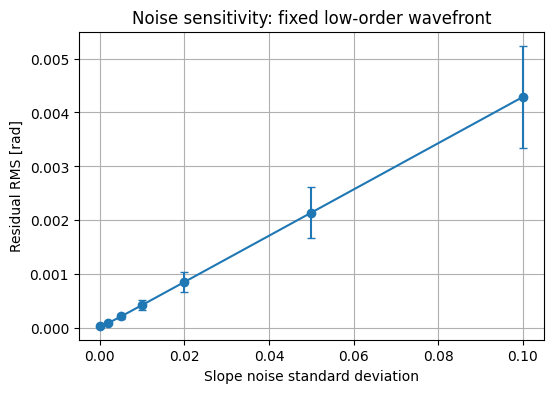

In [10]:
noise_values = np.array([0.0, 0.002, 0.005, 0.01, 0.02, 0.05, 0.10])

noise_fixed, mean_fixed, std_fixed = noise_sensitivity_curve(
    W_fixed,
    X,
    Y,
    mask,
    modes,
    n_lenslets=12,
    noise_values=noise_values,
    n_trials=20,
)

plt.figure(figsize=(6, 4))
plt.errorbar(
    noise_fixed,
    mean_fixed,
    yerr=std_fixed,
    marker="o",
    capsize=3,
)
plt.xlabel("Slope noise standard deviation")
plt.ylabel("Residual RMS [rad]")
plt.title("Noise sensitivity: fixed low-order wavefront")
plt.grid(True)
plt.show()

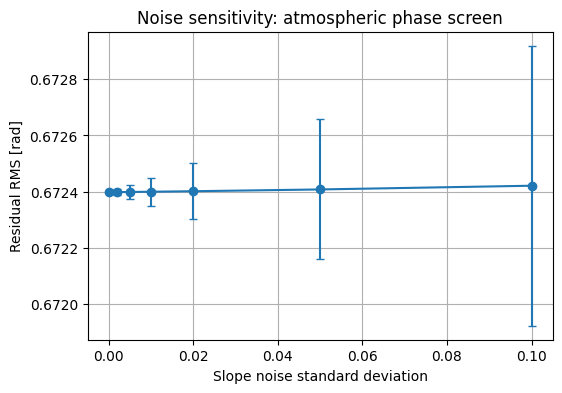

In [8]:
noise_atm, mean_atm, std_atm = noise_sensitivity_curve(
    W_atm,
    X,
    Y,
    mask,
    modes,
    n_lenslets=14,
    noise_values=noise_values,
    n_trials=20,
)

plt.figure(figsize=(6, 4))
plt.errorbar(
    noise_atm,
    mean_atm,
    yerr=std_atm,
    marker="o",
    capsize=3,
)
plt.xlabel("Slope noise standard deviation")
plt.ylabel("Residual RMS [rad]")
plt.title("Noise sensitivity: atmospheric phase screen")
plt.grid(True)
plt.show()

The impact of sub-aperture quantity on the quality of reconstruction

In [12]:
def lenslet_number_scan(
    W_true,
    X,
    Y,
    mask,
    modes,
    lenslet_values=None,
    noise_std=0.0,
):
    """
    Scan number of lenslets across the pupil and compute residual RMS.
    """
    if lenslet_values is None:
        lenslet_values = np.array([6, 8, 10, 12, 14, 16, 20, 24])

    residual_values = []
    rank_values = []
    n_subap_values = []

    for n_lenslets in lenslet_values:
        result = run_wfs_reconstruction(
            W_true,
            X,
            Y,
            mask,
            modes,
            n_lenslets=int(n_lenslets),
            noise_std=noise_std,
            seed=1,
        )

        residual_values.append(result["residual_rms"])
        rank_values.append(result["rank"])
        n_subap_values.append(len(result["centers"]))

    return (
        np.array(lenslet_values),
        np.array(residual_values),
        np.array(rank_values),
        np.array(n_subap_values),
    )

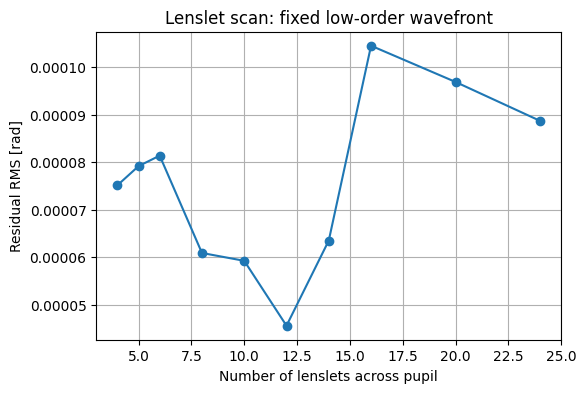

n_lenslets =  4, valid subapertures =  12, rank = 10, residual RMS = 7.5170e-05
n_lenslets =  5, valid subapertures =  21, rank = 10, residual RMS = 7.9200e-05
n_lenslets =  6, valid subapertures =  32, rank = 10, residual RMS = 8.1408e-05
n_lenslets =  8, valid subapertures =  52, rank = 10, residual RMS = 6.0919e-05
n_lenslets = 10, valid subapertures =  80, rank = 10, residual RMS = 5.9271e-05
n_lenslets = 12, valid subapertures = 112, rank = 10, residual RMS = 4.5609e-05
n_lenslets = 14, valid subapertures = 156, rank = 10, residual RMS = 6.3538e-05
n_lenslets = 16, valid subapertures = 208, rank = 10, residual RMS = 1.0454e-04
n_lenslets = 20, valid subapertures = 316, rank = 10, residual RMS = 9.6912e-05
n_lenslets = 24, valid subapertures = 450, rank = 10, residual RMS = 8.8721e-05


In [13]:
lenslet_values = np.array([4, 5, 6, 8, 10, 12, 14, 16, 20, 24])

lens_fixed, res_fixed, rank_fixed, nsub_fixed = lenslet_number_scan(
    W_fixed,
    X,
    Y,
    mask,
    modes,
    lenslet_values=lenslet_values,
    noise_std=0.0,
)

plt.figure(figsize=(6, 4))
plt.plot(
    lens_fixed,
    res_fixed,
    marker="o",
)
plt.xlabel("Number of lenslets across pupil")
plt.ylabel("Residual RMS [rad]")
plt.title("Lenslet scan: fixed low-order wavefront")
plt.grid(True)
plt.show()

for n, nsub, rank, res in zip(lens_fixed, nsub_fixed, rank_fixed, res_fixed):
    print(
        f"n_lenslets = {n:2d}, "
        f"valid subapertures = {nsub:3d}, "
        f"rank = {rank:2d}, "
        f"residual RMS = {res:.4e}"
    )

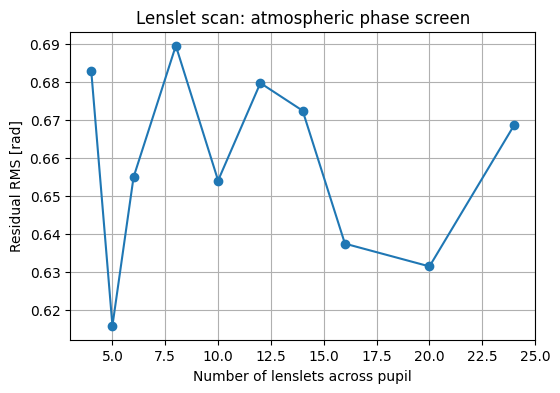

n_lenslets =  4, valid subapertures =  12, rank = 10, residual RMS = 6.8274e-01
n_lenslets =  5, valid subapertures =  21, rank = 10, residual RMS = 6.1580e-01
n_lenslets =  6, valid subapertures =  32, rank = 10, residual RMS = 6.5490e-01
n_lenslets =  8, valid subapertures =  52, rank = 10, residual RMS = 6.8951e-01
n_lenslets = 10, valid subapertures =  80, rank = 10, residual RMS = 6.5402e-01
n_lenslets = 12, valid subapertures = 112, rank = 10, residual RMS = 6.7968e-01
n_lenslets = 14, valid subapertures = 156, rank = 10, residual RMS = 6.7240e-01
n_lenslets = 16, valid subapertures = 208, rank = 10, residual RMS = 6.3740e-01
n_lenslets = 20, valid subapertures = 316, rank = 10, residual RMS = 6.3141e-01
n_lenslets = 24, valid subapertures = 450, rank = 10, residual RMS = 6.6853e-01


In [14]:
lens_atm, res_atm, rank_atm, nsub_atm = lenslet_number_scan(
    W_atm,
    X,
    Y,
    mask,
    modes,
    lenslet_values=lenslet_values,
    noise_std=0.0,
)

plt.figure(figsize=(6, 4))
plt.plot(
    lens_atm,
    res_atm,
    marker="o",
)
plt.xlabel("Number of lenslets across pupil")
plt.ylabel("Residual RMS [rad]")
plt.title("Lenslet scan: atmospheric phase screen")
plt.grid(True)
plt.show()

for n, nsub, rank, res in zip(lens_atm, nsub_atm, rank_atm, res_atm):
    print(
        f"n_lenslets = {n:2d}, "
        f"valid subapertures = {nsub:3d}, "
        f"rank = {rank:2d}, "
        f"residual RMS = {res:.4e}"
    )

In this experiment, increasing the number of lenslets does not necessarily lead to a monotonic decrease of the residual wavefront error. This is because the number of reconstructed modes is kept fixed. The Shack-Hartmann sensor samples the local slopes more finely as the number of sub-apertures increases, but the reconstructor still projects the measured slopes onto the same low-order Zernike-like modal basis.

For atmospheric turbulence, the wavefront contains high-spatial-frequency aberrations that cannot be represented by this limited modal basis. Therefore, increasing the WFS sampling alone does not remove the high-order residual. In some cases, finer sampling can even introduce more high-frequency slope information into the least-squares fit, which may slightly change the estimated low-order coefficients and produce non-monotonic residual RMS behavior.

A physically more complete AO simulation would increase both the WFS sampling and the number of controllable modes or DM actuators.

An increased number of lenslets enhances slope sampling;
however, the reconstruction basis remains limited to low-order Zernike modes,
consequently, high-order turbulent structures still cannot be fitted.

Low order AO Correction demo

In [16]:
result_atm = run_wfs_reconstruction(
    W_atm,
    X,
    Y,
    mask,
    modes,
    n_lenslets=14,
    noise_std=0.01,
    seed=2,
)

W_rec = result_atm["W_rec"]
W_corrected = result_atm["residual"]

print(f"Atmospheric RMS before correction: {rms(W_atm, mask):.4f} rad")
print(f"Residual RMS after correction:     {rms(W_corrected, mask):.4f} rad")
print(f"RMS reduction factor:              {rms(W_atm, mask) / rms(W_corrected, mask):.3f}")

Atmospheric RMS before correction: 0.9999 rad
Residual RMS after correction:     0.6724 rad
RMS reduction factor:              1.487


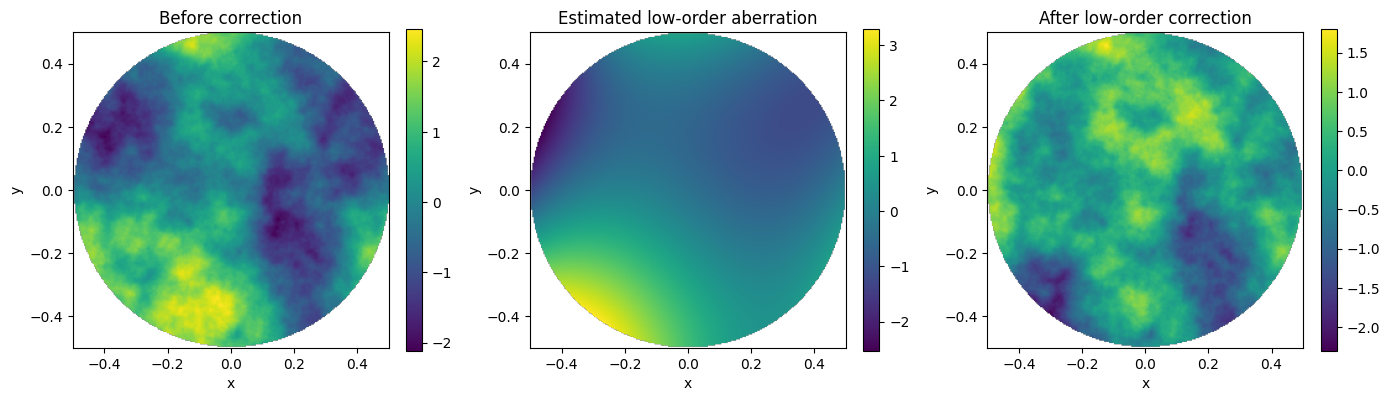

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

im0 = axes[0].imshow(
    W_atm,
    extent=extent,
    origin="lower",
)
axes[0].set_title("Before correction")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(
    W_rec,
    extent=extent,
    origin="lower",
)
axes[1].set_title("Estimated low-order aberration")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(
    W_corrected,
    extent=extent,
    origin="lower",
)
axes[2].set_title("After low-order correction")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

Comparison of different turbulence

In [18]:
seeds = [1, 2, 3, 4, 5, 10, 20, 30]
before_values = []
after_values = []

for seed in seeds:
    W_tmp = make_random_atmospheric_wavefront(
        N=N,
        dx=dx,
        diameter=diameter,
        r0=0.20,
        L0=25.0,
        seed=seed,
        target_rms_rad=1.0,
    )

    result_tmp = run_wfs_reconstruction(
        W_tmp,
        X,
        Y,
        mask,
        modes,
        n_lenslets=14,
        noise_std=0.01,
        seed=100 + seed,
    )

    before_values.append(rms(W_tmp, mask))
    after_values.append(result_tmp["residual_rms"])

before_values = np.array(before_values)
after_values = np.array(after_values)

print(f"Mean RMS before correction: {np.mean(before_values):.4f} rad")
print(f"Mean RMS after correction:  {np.mean(after_values):.4f} rad")
print(f"Mean reduction factor:      {np.mean(before_values / after_values):.3f}")

Mean RMS before correction: 1.0003 rad
Mean RMS after correction:  0.5510 rad
Mean reduction factor:      1.859


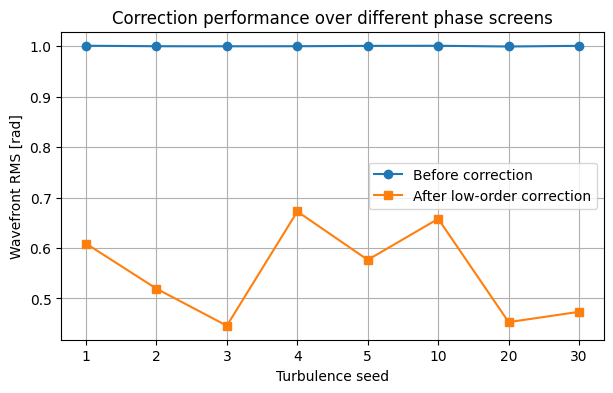

In [19]:
x = np.arange(len(seeds))

plt.figure(figsize=(7, 4))

plt.plot(
    x,
    before_values,
    marker="o",
    label="Before correction",
)

plt.plot(
    x,
    after_values,
    marker="s",
    label="After low-order correction",
)

plt.xticks(x, seeds)
plt.xlabel("Turbulence seed")
plt.ylabel("Wavefront RMS [rad]")
plt.title("Correction performance over different phase screens")
plt.grid(True)
plt.legend()
plt.show()

PSF and Strehl-ratio

In [20]:
def compute_psf_from_phase(phase_rad, mask, pad_factor=4):
    """
    Compute focal-plane PSF from pupil phase.

    Parameters
    ----------
    phase_rad : ndarray
        Phase aberration in radians.
    mask : ndarray
        Pupil mask.
    pad_factor : int
        Zero-padding factor for better PSF sampling.

    Returns
    -------
    psf : ndarray
        Normalized PSF.
    """
    N = phase_rad.shape[0]

    pupil_field = np.zeros_like(phase_rad, dtype=complex)
    phase_clean = np.nan_to_num(phase_rad, nan=0.0)

    pupil_field[mask] = np.exp(1j * phase_clean[mask])

    pad_N = pad_factor * N
    padded = np.zeros((pad_N, pad_N), dtype=complex)

    start = (pad_N - N) // 2
    end = start + N
    padded[start:end, start:end] = pupil_field

    focal_field = np.fft.fftshift(
        np.fft.fft2(
            np.fft.ifftshift(padded)
        )
    )

    psf = np.abs(focal_field) ** 2
    psf /= np.sum(psf)

    return psf


def strehl_ratio(phase_rad, mask, pad_factor=4):
    """
    Compute approximate Strehl ratio.

    Strehl = peak aberrated PSF / peak diffraction-limited PSF
    """
    psf_aberrated = compute_psf_from_phase(
        phase_rad,
        mask,
        pad_factor=pad_factor,
    )

    ideal_phase = np.zeros_like(phase_rad)

    psf_ideal = compute_psf_from_phase(
        ideal_phase,
        mask,
        pad_factor=pad_factor,
    )

    return np.max(psf_aberrated) / np.max(psf_ideal)

In [21]:
strehl_before = strehl_ratio(
    W_atm,
    mask,
    pad_factor=4,
)

strehl_after = strehl_ratio(
    W_corrected,
    mask,
    pad_factor=4,
)

print(f"Approximate Strehl before correction: {strehl_before:.4f}")
print(f"Approximate Strehl after correction:  {strehl_after:.4f}")

Approximate Strehl before correction: 0.4567
Approximate Strehl after correction:  0.6930


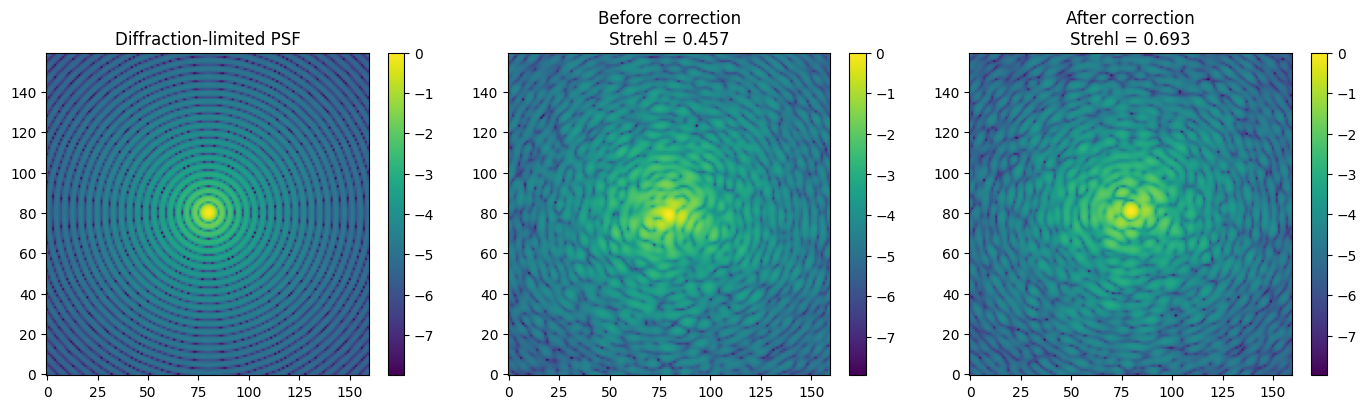

In [22]:
psf_before = compute_psf_from_phase(
    W_atm,
    mask,
    pad_factor=4,
)

psf_after = compute_psf_from_phase(
    W_corrected,
    mask,
    pad_factor=4,
)

psf_ideal = compute_psf_from_phase(
    np.zeros_like(W_atm),
    mask,
    pad_factor=4,
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

crop = 80
center = psf_before.shape[0] // 2
sl = slice(center - crop, center + crop)

im0 = axes[0].imshow(
    np.log10(psf_ideal[sl, sl] / np.max(psf_ideal) + 1e-8),
    origin="lower",
)
axes[0].set_title("Diffraction-limited PSF")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(
    np.log10(psf_before[sl, sl] / np.max(psf_before) + 1e-8),
    origin="lower",
)
axes[1].set_title(f"Before correction\nStrehl = {strehl_before:.3f}")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(
    np.log10(psf_after[sl, sl] / np.max(psf_after) + 1e-8),
    origin="lower",
)
axes[2].set_title(f"After correction\nStrehl = {strehl_after:.3f}")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

In [23]:
from mpl_toolkits.mplot3d import Axes3D


def plot_psf_surface_3d(
    psf,
    title="PSF",
    crop=80,
    stride=2,
    log_scale=True,
):
    """
    Plot PSF as a 3D surface.

    Parameters
    ----------
    psf : ndarray
        Normalized PSF.
    title : str
        Plot title.
    crop : int
        Half-size of central crop.
    stride : int
        Downsampling stride for plotting.
    log_scale : bool
        If True, plot log10 normalized intensity.
        If False, plot linear normalized intensity.
    """
    center = psf.shape[0] // 2
    sl = slice(center - crop, center + crop)

    psf_crop = psf[sl, sl]
    psf_crop = psf_crop / np.max(psf_crop)

    if log_scale:
        Z = np.log10(psf_crop + 1e-8)
        zlabel = "log10 normalized intensity"
    else:
        Z = psf_crop
        zlabel = "normalized intensity"

    Z = Z[::stride, ::stride]

    ny, nx = Z.shape
    x = np.arange(nx)
    y = np.arange(ny)
    Xp, Yp = np.meshgrid(x, y)

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    ax.plot_surface(
        Xp,
        Yp,
        Z,
        linewidth=0,
        antialiased=True,
    )

    ax.set_title(title)
    ax.set_xlabel("focal-plane x [pixel]")
    ax.set_ylabel("focal-plane y [pixel]")
    ax.set_zlabel(zlabel)

    plt.tight_layout()
    plt.show()

In [26]:
def plot_three_psf_surfaces_3d_same_scale(
    psf_ideal,
    psf_before,
    psf_after,
    crop=70,
    stride=2,
    log_scale=True,
):
    """
    Plot ideal, before-correction, and after-correction PSFs
    using the same absolute normalization.

    All PSFs are normalized by the peak of the diffraction-limited PSF.
    This makes the Strehl-ratio difference visually meaningful.
    """
    reference_peak = np.max(psf_ideal)

    strehl_before = np.max(psf_before) / reference_peak
    strehl_after = np.max(psf_after) / reference_peak

    psfs = [
        psf_ideal / reference_peak,
        psf_before / reference_peak,
        psf_after / reference_peak,
    ]

    titles = [
        "Diffraction-limited PSF\nStrehl = 1.000",
        f"Before correction\nStrehl = {strehl_before:.3f}",
        f"After correction\nStrehl = {strehl_after:.3f}",
    ]

    fig = plt.figure(figsize=(18, 5))

    for i, (psf_norm, title) in enumerate(zip(psfs, titles), start=1):
        center = psf_norm.shape[0] // 2
        sl = slice(center - crop, center + crop)

        psf_crop = psf_norm[sl, sl]

        if log_scale:
            Z = np.log10(psf_crop + 1e-8)
            zlabel = "log10(I / I_ideal_peak)"
            zlim = (-8, 0)
        else:
            Z = psf_crop
            zlabel = "I / I_ideal_peak"
            zlim = (0, 1)

        Z = Z[::stride, ::stride]

        ny, nx = Z.shape
        x = np.arange(nx)
        y = np.arange(ny)
        Xp, Yp = np.meshgrid(x, y)

        ax = fig.add_subplot(1, 3, i, projection="3d")

        ax.plot_surface(
            Xp,
            Yp,
            Z,
            linewidth=0,
            antialiased=True,
        )

        ax.set_title(title)
        ax.set_xlabel("x [pixel]")
        ax.set_ylabel("y [pixel]")
        ax.set_zlabel(zlabel)
        ax.set_zlim(*zlim)
        ax.view_init(elev=30, azim=-60)

    plt.tight_layout()
    plt.show()

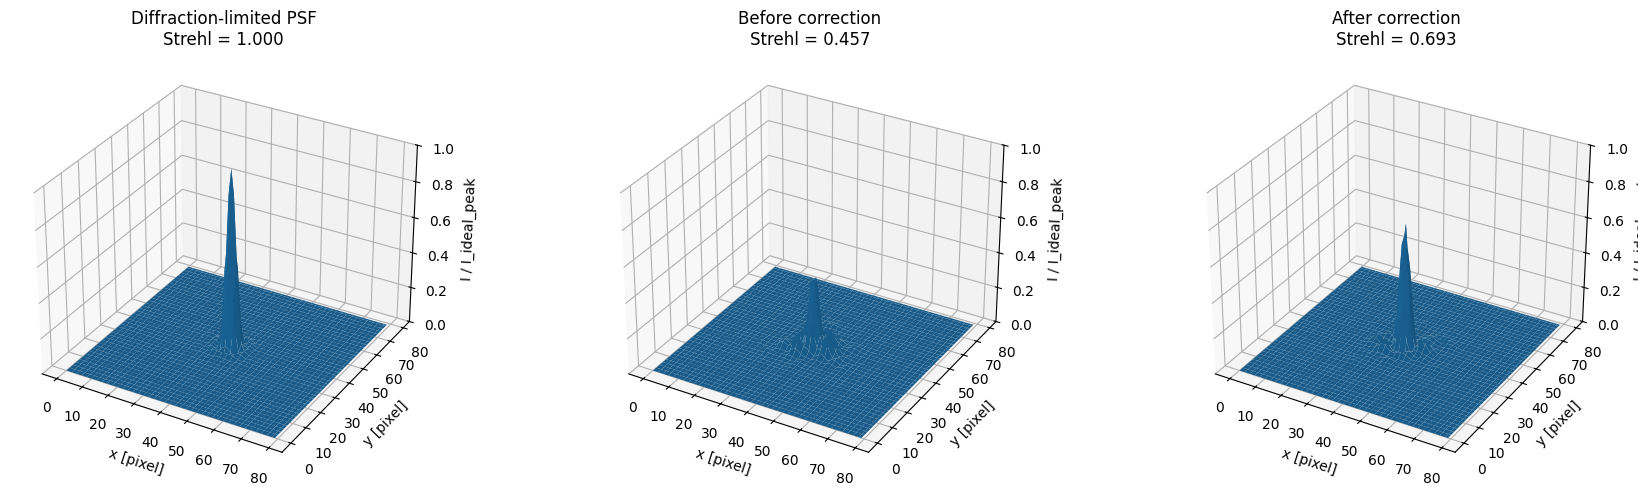

In [28]:
plot_three_psf_surfaces_3d_same_scale(
    psf_ideal,
    psf_before,
    psf_after,
    crop=40,
    stride=1,
    log_scale=False,
)

In [29]:
def radial_profile(psf, center=None):
    """
    Compute azimuthally averaged radial profile of a PSF.
    """
    ny, nx = psf.shape

    if center is None:
        center = (nx // 2, ny // 2)

    x = np.arange(nx)
    y = np.arange(ny)
    Xp, Yp = np.meshgrid(x, y)

    r = np.sqrt((Xp - center[0])**2 + (Yp - center[1])**2)
    r_int = r.astype(int)

    profile = np.bincount(
        r_int.ravel(),
        weights=psf.ravel(),
    ) / np.bincount(r_int.ravel())

    radius = np.arange(len(profile))

    return radius, profile